# Classificador de fotos — ambiente e conservação

Treino com **somente a imagem** como entrada (nenhuma variável tabular).
Rótulos: `dados/rotulos_conservacao.csv` (humanos). Execute antes:

```bash
uv run python scripts/treinar_classificador_fotos.py
uv run python scripts/avaliar_modelo.py   # só para a seção de avaliação
```

A célula de configuração **aborta** se algum artefato vier de outra execução —
os números de treino (OOF/holdout) e os de avaliação (192/224 px) precisam ser
do mesmo treino. O holdout é uma fatia travada, nunca usada no CV nem na
escolha de época.

In [1]:
import json, sys
from datetime import datetime
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))
from classificador_fotos import AMBIENTES, LABELS

SAIDA = REPO / "dados" / "modelo_fotos"
ARQ = SAIDA / "metricas_fotos.json"
if not ARQ.exists():
    raise SystemExit("rode uv run python scripts/treinar_classificador_fotos.py")

MET = json.loads(ARQ.read_text(encoding="utf-8"))
IMG = MET["config"]["img"]
GERADO = datetime.fromisoformat(MET["gerado"])

# Tudo abaixo tem que vir da MESMA execucao. Artefato velho com treino novo ja
# colocou recall 0.17 e 0.37 para a mesma classe neste notebook.
problemas = []
AVA_ARQ = SAIDA / "metricas_avaliacao.json"
if AVA_ARQ.exists():
    ava_gerado = datetime.fromisoformat(
        json.loads(AVA_ARQ.read_text(encoding="utf-8"))["gerado"])
    if ava_gerado < GERADO:
        problemas.append(f"metricas_avaliacao.json de {ava_gerado:%d/%m %H:%M} "
                         f"< treino de {GERADO:%d/%m %H:%M}")
for tarefa in ("ambiente", "conservacao"):
    p = SAIDA / f"probs_oof_{tarefa}_{IMG}.csv"
    if not p.exists():
        problemas.append(f"falta {p.name} (e gerado pelo treino)")
    elif datetime.fromtimestamp(p.stat().st_mtime) < GERADO:
        problemas.append(f"{p.name} mais antigo que o treino")
if problemas:
    raise SystemExit("artefatos de execucoes diferentes:\n  - " + "\n  - ".join(problemas)
                     + "\nrode scripts/treinar_classificador_fotos.py e, para a"
                       " secao de avaliacao, scripts/avaliar_modelo.py")

print(MET["base"], "|", MET["gerado"], "|", IMG, "px | holdout",
      MET["config"].get("holdout"), "| n", MET.get("n_rotulos"))
print(MET["config"])

c:\Users\jefer\Documents\Ciencia-de-dados\Preco-Imoveis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


facebook/convnext-tiny-224 | 2026-10-27T09:57:38 | 192 px | holdout 0.2 | n 775
{'tarefa': 'ambas', 'folds': 5, 'epocas': 18, 'img': 192, 'batch': 24, 'paciencia': 4, 'selecao': 'logloss', 'expandir': False, 'siblings_max': 8, 'holdout': 0.2, 'limite': 0, 'rapido': False, 'parquet': 'C:\\Users\\jefer\\Documents\\Ciencia-de-dados\\Preco-Imoveis\\dados\\joinville\\joinville_imoveis_limpo_2026-10.parquet'}


775 fotos humanas | ambiente: {'interna': 499, 'externa': 276}
conservacao no CV: 620 | origens: {'humano': 620}
anuncios com fotos irmas avaliadas: 775


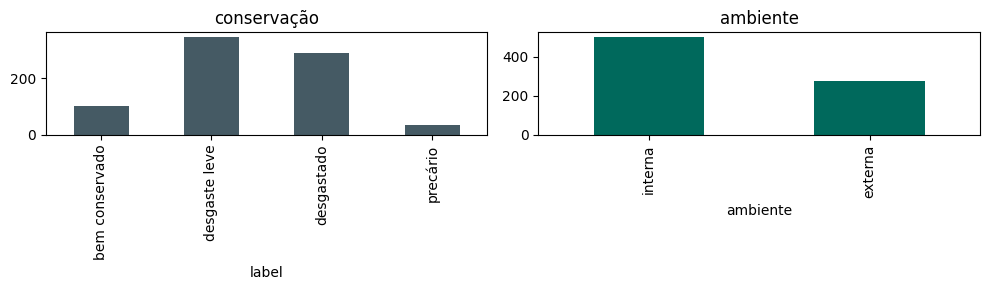

In [2]:
hum = pd.read_csv(REPO / "dados" / "rotulos_conservacao.csv",
                   dtype=str, keep_default_na=False)
print(len(hum), "fotos humanas | ambiente:", hum.ambiente.value_counts().to_dict())
if (SAIDA / "oof_conservacao.csv").exists():
    oof = pd.read_csv(SAIDA / "oof_conservacao.csv")
    print("conservacao no CV:", len(oof), "| origens:", oof.origem.value_counts().to_dict())
if (SAIDA / "consistencia_anuncios.csv").exists():
    print("anuncios com fotos irmas avaliadas:",
          len(pd.read_csv(SAIDA / "consistencia_anuncios.csv")))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
hum.label.value_counts().reindex(LABELS).plot.bar(ax=ax[0], color="#455a64", title="conservação")
hum.ambiente.value_counts().plot.bar(ax=ax[1], color="#00695c", title="ambiente")
plt.tight_layout()

acc 89.7% | balanced 87.9% | macro-F1 0.89 | IC [0.849 0.908] | n=620


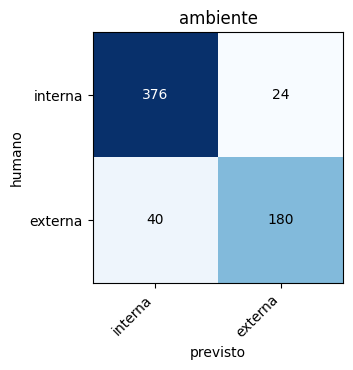

In [3]:
def mostrar(r, titulo):
    m = np.array(r["matriz"])
    fig, ax = plt.subplots(figsize=(4.4, 3.8))
    ax.imshow(m, cmap="Blues")
    ax.set_xticks(range(len(r["nomes"])), r["nomes"], rotation=45, ha="right")
    ax.set_yticks(range(len(r["nomes"])), r["nomes"])
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, m[i, j], ha="center", va="center",
                    color="white" if m[i, j] > m.max() / 2 else "black")
    ax.set_xlabel("previsto"); ax.set_ylabel("humano"); ax.set_title(titulo)
    plt.tight_layout()

r = MET["ambiente"]
print(f"acc {r['acc']:.1%} | balanced {r['balanced_acc']:.1%} | "
      f"macro-F1 {r['macro_f1']:.2f} | IC {np.round(r['ic'], 3)} | n={r['n']}")
mostrar(r, "ambiente")

kappa 0.514 | linear 0.290 | macro-F1 0.49 | bal_acc 0.475 | acc 55.3% | IC [0.452 0.569] | n=620
recall: {'bem conservado': 0.4, 'desgaste leve': 0.61, 'desgastado': 0.57, 'precário': 0.32}
holdout: n=155 kappa 0.443 IC [0.312 0.564] | bal_acc 0.436


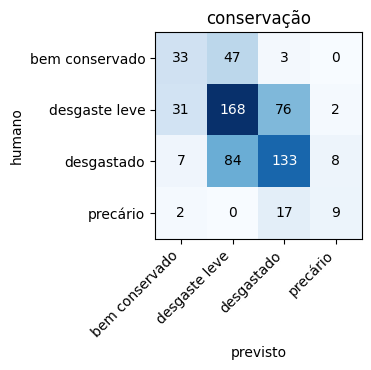

In [4]:
r = MET["conservacao"]
print(f"kappa {r['kappa']:.3f} | linear {r.get('kappa_linear', float('nan')):.3f} "
      f"| macro-F1 {r['macro_f1']:.2f} | bal_acc {r['balanced_acc']:.3f} "
      f"| acc {r['acc']:.1%} | IC {np.round(r['ic'], 3)} | n={r['n']}")
print("recall:", {k: round(v, 2) for k, v in r["recall_por_classe"].items()})
h = r.get("holdout")
if h:
    print(f"holdout: n={h['n']} kappa {h['kappa']:.3f} "
          f"IC {np.round(h['ic'], 3)} | bal_acc {h['balanced_acc']:.3f}")
mostrar(r, "conservação")

# Avaliação nas imagens

Probabilidades **OOF** (cada foto prevista pelo fold que não a viu) e inspeção visual
dos erros. O `probs_oof_*.csv` é gravado pelo próprio treino; `metricas_avaliacao.json`
e as resoluções vêm de `uv run python scripts/avaliar_modelo.py`.

In [5]:
AVA_ARQ = SAIDA / "metricas_avaliacao.json"
if not AVA_ARQ.exists():
    raise SystemExit("rode uv run python scripts/avaliar_modelo.py")
AVA = json.loads(AVA_ARQ.read_text(encoding="utf-8"))
if AVA.get("treino_gerado") != MET["gerado"]:
    raise SystemExit(f"metricas_avaliacao.json e de outro treino "
                     f"({AVA.get('treino_gerado')} vs {MET['gerado']}); "
                     "rode uv run python scripts/avaliar_modelo.py")

linhas = []
for tarefa, info in AVA["tarefas"].items():
    for size, r in info["resolucoes"].items():
        chave = "kappa" if "kappa" in r else "balanced_acc"
        linhas.append({
            "tarefa": tarefa, "px": int(size),
            "n_cv": r["n"], "n_holdout": info.get("n_holdout"),
            "metrica": chave, "valor": r[chave], "acc": r["acc"],
            "bal_acc": r["balanced_acc"], "macro_f1": r["macro_f1"],
            "IC95": f"{r['ic'][0]:.3f}-{r['ic'][1]:.3f}",
            "folds": f"{np.mean(r['folds']):.3f}±{np.std(r['folds']):.3f}",
            "div_vs_treino": r.get("divergentes_vs_treino", "")})
print("CV (5 folds, fotos de treino/validacao cruzada):")
print(pd.DataFrame(linhas).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

linhas = []
for tarefa in ("ambiente", "conservacao"):
    r = AVA["tarefas"][tarefa]["resolucoes"][str(IMG)]
    h = r.get("holdout")
    if not h:
        continue
    chave = "kappa" if "kappa" in h else "balanced_acc"
    linhas.append({"tarefa": tarefa, "px": IMG, "n_holdout": h["n"],
                   "metrica": chave, "valor": h[chave], "acc": h["acc"],
                   "bal_acc": h["balanced_acc"], "macro_f1": h["macro_f1"],
                   "IC95": f"{h['ic'][0]:.3f}-{h['ic'][1]:.3f}"})
print(f"\nholdout {IMG}px (fatia travada, nunca usada no CV):")
print(pd.DataFrame(linhas).to_string(index=False, float_format=lambda v: f"{v:.3f}"))

CV (5 folds, fotos de treino/validacao cruzada):
     tarefa  px  n_cv  n_holdout      metrica  valor   acc  bal_acc  macro_f1        IC95       folds div_vs_treino
   ambiente 192   620        155 balanced_acc  0.879 0.897    0.879     0.885 0.849-0.908 0.879±0.014             0
   ambiente 224   620        155 balanced_acc  0.875 0.894    0.875     0.881 0.845-0.904 0.875±0.022              
conservacao 192   620        155        kappa  0.514 0.553    0.475     0.492 0.452-0.569 0.513±0.059             0
conservacao 224   620        155        kappa  0.498 0.547    0.456     0.477 0.436-0.553 0.496±0.106              

holdout 192px (fatia travada, nunca usada no CV):
     tarefa  px  n_holdout      metrica  valor   acc  bal_acc  macro_f1        IC95
   ambiente 192        155 balanced_acc  0.896 0.916    0.896     0.906 0.841-0.945
conservacao 192        155        kappa  0.443 0.587    0.436     0.433 0.312-0.564


In [6]:
import metricas_fotos as mf

RES, PROBS = {}, {}
for tarefa, nomes in (("ambiente", AMBIENTES), ("conservacao", LABELS)):
    d = pd.read_csv(SAIDA / f"probs_oof_{tarefa}_{IMG}.csv")
    P = d[[f"p{i}" for i in range(len(nomes))]].values
    RES[tarefa] = mf.indices(d.y.values, P, nomes)
    PROBS[tarefa] = (d, P)

print(f"CV: {RES['ambiente']['n']} fotos | holdout: "
      f"{AVA['tarefas']['ambiente'].get('n_holdout')} fotos")
print("resumo (CV)")
print(mf.tabela_indices(RES).to_string(index=False,
      float_format=lambda v: f"{v:.3f}"))

for tarefa in ("ambiente", "conservacao"):
    print(f"\n{tarefa} - por classe")
    print(mf.tabela_classes(RES[tarefa]).to_string(index=False,
          float_format=lambda v: f"{v:.2f}"))
    print("matriz normalizada por linha (linha = humano)")
    print(mf.matriz_normalizada(RES[tarefa]).round(2).to_string())

d, _ = PROBS["conservacao"]
dist = (d["pred"] - d["y"]).abs()
print(f"\nconservacao: {int((dist > 0).sum())} erros | "
      f"{100 * (dist[dist > 0] == 1).mean():.1f}% deles sao de 1 nivel | "
      f"erros de 2+ niveis: {int((dist >= 2).sum())}")

for tarefa in ("ambiente", "conservacao"):
    h = AVA["tarefas"][tarefa]["resolucoes"][str(IMG)].get("holdout")
    if not h:
        continue
    m = np.array(h["matriz"], dtype=float)
    print(f"\nholdout {tarefa} (n={h['n']}) matriz por linha:")
    print(pd.DataFrame(m / np.maximum(m.sum(1, keepdims=True), 1),
                       index=h["nomes"], columns=h["nomes"]).round(2).to_string())
    if "recall_por_classe" in h:
        print("recall:", {k: round(v, 2) for k, v in h["recall_por_classe"].items()})

CV: 620 fotos | holdout: 155 fotos
resumo (CV)
     tarefa   n   acc  balanced_acc  macro_f1  weighted_f1  especificidade_macro
   ambiente 620 0.897         0.879     0.885        0.896                 0.879
conservacao 620 0.553         0.475     0.492        0.550                 0.820

ambiente - por classe
 classe  precisao  recall  especificidade   f1   n
interna      0.90    0.94            0.82 0.92 400
externa      0.88    0.82            0.94 0.85 220
matriz normalizada por linha (linha = humano)
         interna  externa
interna     0.94     0.06
externa     0.18     0.82

conservacao - por classe
        classe  precisao  recall  especificidade   f1   n
bem conservado      0.45    0.40            0.93 0.42  83
 desgaste leve      0.56    0.61            0.62 0.58 277
    desgastado      0.58    0.57            0.75 0.58 232
      precário      0.47    0.32            0.98 0.38  28
matriz normalizada por linha (linha = humano)
                bem conservado  desgaste leve  d

equilibrio: |acc - bal_acc| perto de 0 = desempenho parelho entre classes
     tarefa        conjunto    acc  vs maioria  bal_acc  macro_f1  acc - bal_acc
   ambiente      CV (n=620) +0.897      +0.252   +0.879    +0.885         +0.018
   ambiente holdout (n=155) +0.916         NaN   +0.896    +0.906         +0.021
conservacao      CV (n=620) +0.553      +0.106   +0.475    +0.492         +0.079
conservacao holdout (n=155) +0.587         NaN   +0.436    +0.433         +0.151


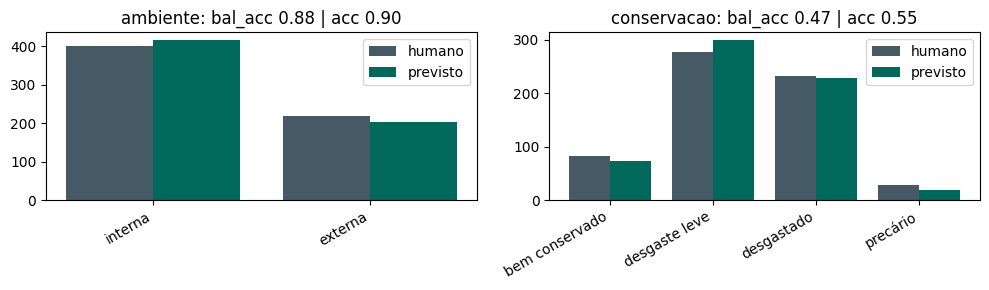

In [7]:
linhas = []
for tarefa, nomes in (("ambiente", AMBIENTES), ("conservacao", LABELS)):
    r, (d, _) = RES[tarefa], PROBS[tarefa]
    maioria = np.bincount(d.y.values).max() / len(d)
    linhas.append({"tarefa": tarefa, "conjunto": f"CV (n={r['n']})",
                   "acc": r["acc"], "vs maioria": r["acc"] - maioria,
                   "bal_acc": r["balanced_acc"], "macro_f1": r["macro_f1"],
                   "acc - bal_acc": r["acc"] - r["balanced_acc"]})
    h = AVA["tarefas"][tarefa]["resolucoes"][str(IMG)].get("holdout")
    if h:
        linhas.append({"tarefa": tarefa, "conjunto": f"holdout (n={h['n']})",
                       "acc": h["acc"], "vs maioria": np.nan,
                       "bal_acc": h["balanced_acc"], "macro_f1": h["macro_f1"],
                       "acc - bal_acc": h["acc"] - h["balanced_acc"]})
print("equilibrio: |acc - bal_acc| perto de 0 = desempenho parelho entre classes")
print(pd.DataFrame(linhas).to_string(index=False, float_format=lambda v: f"{v:+.3f}"))

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for k, (tarefa, nomes) in enumerate((("ambiente", AMBIENTES), ("conservacao", LABELS))):
    r, (d, _) = RES[tarefa], PROBS[tarefa]
    x = np.arange(len(nomes))
    ax[k].bar(x - 0.2, np.bincount(d.y.values, minlength=len(nomes)), 0.4,
              label="humano", color="#455a64")
    ax[k].bar(x + 0.2, np.bincount(d.pred.values, minlength=len(nomes)), 0.4,
              label="previsto", color="#00695c")
    ax[k].set_xticks(x, nomes, rotation=30, ha="right")
    ax[k].set_title(f"{tarefa}: bal_acc {r['balanced_acc']:.2f} "
                    f"| acc {r['acc']:.2f}")
    ax[k].legend()
plt.tight_layout()

In [8]:
from sklearn.metrics import balanced_accuracy_score, cohen_kappa_score, f1_score

d, P = PROBS["conservacao"]
y4, p4 = d.y.values, P.argmax(1)
yb = (y4 >= 2).astype(int)          # 0 = bem conservado/desgaste leve
predb = ((P[:, 2] + P[:, 3]) >= 0.5).astype(int)
print("bem+leve vs desgastado+precario: "
      f"acc {(yb == predb).mean():.3f} | bal_acc {balanced_accuracy_score(yb, predb):.3f} "
      f"| macro_f1 {f1_score(yb, predb, average='macro'):.3f} "
      f"| QWK {cohen_kappa_score(yb, predb, weights='quadratic'):.3f}")
print(f"4 niveis: QWK {cohen_kappa_score(y4, p4, weights='quadratic'):.3f} | "
      f"linear {cohen_kappa_score(y4, p4):.3f} | "
      f"bal_acc {balanced_accuracy_score(y4, p4):.3f}")

bem+leve vs desgastado+precario: acc 0.731 | bal_acc 0.719 | macro_f1 0.721 | QWK 0.442
4 niveis: QWK 0.514 | linear 0.290 | bal_acc 0.475


In [9]:
d, P = PROBS["conservacao"]
y, p = d.y.values, P.argmax(1)
conf = P.max(1)
margem = np.sort(P, 1)[:, -1] - np.sort(P, 1)[:, -2]

linhas = []
for lo, hi in ((0.25, 0.4), (0.4, 0.5), (0.5, 0.6), (0.6, 0.7),
               (0.7, 0.8), (0.8, 1.01)):
    m = (conf >= lo) & (conf < hi)
    if m.sum():
        linhas.append({"confianca": f"{lo:.2f}-{hi:.2f}", "n": int(m.sum()),
                       "acc": (p[m] == y[m]).mean(), "conf_media": conf[m].mean()})
tab = pd.DataFrame(linhas)
print(tab.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
print(f"ECE {(tab.acc - tab.conf_media).abs().mul(tab.n).sum() / tab.n.sum():.3f}"
      f" | confianca media {conf.mean():.3f}")

erro = p != y
ordem = np.argsort(margem)
print("\nfila de revisao por margem (menor margem primeiro):")
for frac in (0.1, 0.2, 0.3):
    k = int(round(len(y) * frac))
    sel = ordem[:k]
    print(f"  revisar {frac:4.0%} ({k:3d} fotos): {erro[sel].mean():5.1%} de erro na fila, "
          f"pega {erro[sel].sum():3d}/{erro.sum():3d} erros "
          f"({erro[sel].sum() / erro.sum():.1%}) | base {erro.mean():.1%}")

confianca   n   acc  conf_media
0.25-0.40  50 0.400       0.360
0.40-0.50 130 0.415       0.458
0.50-0.60 151 0.603       0.551
0.60-0.70 118 0.534       0.649
0.70-0.80  94 0.638       0.746
0.80-1.01  77 0.714       0.860
ECE 0.081 | confianca media 0.602

fila de revisao por margem (menor margem primeiro):
  revisar  10% ( 62 fotos): 59.7% de erro na fila, pega  37/277 erros (13.4%) | base 44.7%
  revisar  20% (124 fotos): 55.6% de erro na fila, pega  69/277 erros (24.9%) | base 44.7%
  revisar  30% (186 fotos): 55.4% de erro na fila, pega 103/277 erros (37.2%) | base 44.7%


In [10]:
hum = pd.read_csv(REPO / "dados" / "rotulos_conservacao.csv",
                  dtype=str, keep_default_na=False)
hum["valor"] = pd.to_numeric(hum["valor_imovel"], errors="coerce")
d, P = PROBS["conservacao"]
d = d.copy(); d["_i"] = np.arange(len(d))
d = d.merge(hum[["url_foto", "ambiente", "valor"]], on="url_foto", how="left")
d["tercil"] = pd.qcut(d["valor"], 3, labels=["baixo", "medio", "alto"])

linhas = []
for coluna in ("ambiente", "tercil", "fold"):
    for grupo, sub in d.groupby(coluna, observed=True):
        r = mf.indices(sub["y"].values, P[sub["_i"].values], LABELS)
        linhas.append({"fatia": coluna, "grupo": str(grupo), "n": r["n"],
                       "acc": r["acc"], "macro_f1": r["macro_f1"]})
print(pd.DataFrame(linhas).to_string(index=False, float_format=lambda v: f"{v:.3f}"))


   fatia   grupo   n   acc  macro_f1
ambiente externa 220 0.509     0.491
ambiente interna 400 0.578     0.450
  tercil   baixo 209 0.569     0.549
  tercil   medio 205 0.561     0.413
  tercil    alto 206 0.529     0.442
    fold       1 125 0.560     0.492
    fold       2 124 0.524     0.493
    fold       3 124 0.573     0.511
    fold       4 124 0.532     0.403
    fold       5 123 0.577     0.556


erros de 2 niveis: 12 fotos


humano: desgastadoprevisto: bem conservado p=0.88margem 0.82america R$ 675.000,humano: desgaste leveprevisto: precário p=0.83margem 0.70paranaguamirim R$ 450.000,humano: desgastadoprevisto: bem conservado p=0.63margem 0.47saguacu R$ 350.000,humano: desgastadoprevisto: bem conservado p=0.64margem 0.37itaum R$ 343.599,humano: bem conservadoprevisto: desgastado p=0.56margem 0.35bom retiro R$ 465.000,humano: desgastadoprevisto: bem conservado p=0.63margem 0.34saguacu R$ 454.399
humano: bem conservadoprevisto: desgastado p=0.47margem 0.23atiradores R$ 1.060.000,humano: desgastadoprevisto: bem conservado p=0.50margem 0.17santo antonio R$ 890.000,humano: bem conservadoprevisto: desgastado p=0.46margem 0.15saguacu R$ 385.000,humano: desgaste leveprevisto: precário p=0.41margem 0.13anita garibaldi R$ 858.816,humano: desgastadoprevisto: bem conservado p=0.33margem 0.04itinga R$ 990.000,humano: desgastadoprevisto: bem conservado p=0.43margem 0.01saguacu R$ 315.000

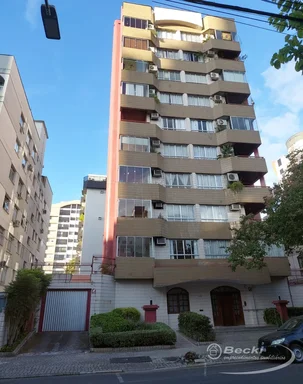
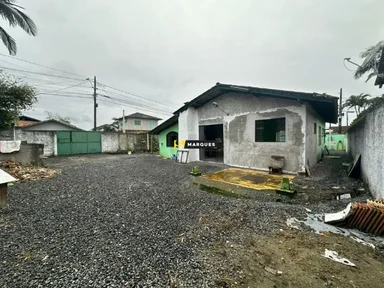
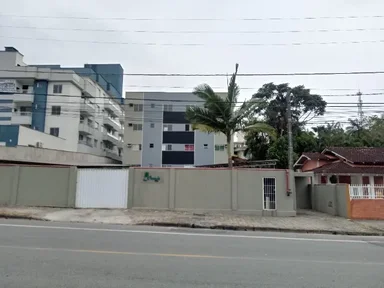
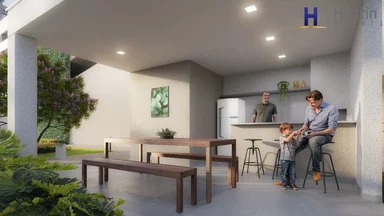
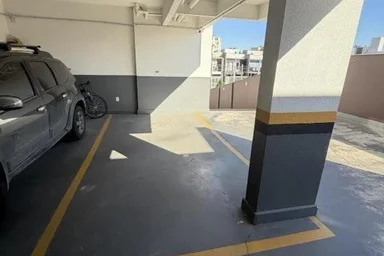
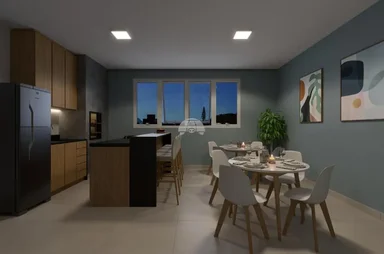
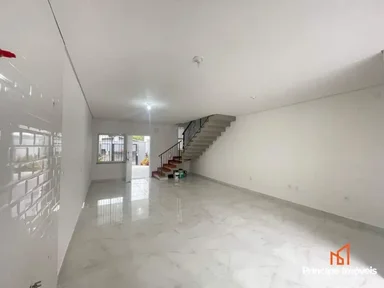
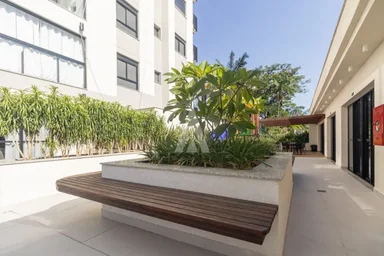
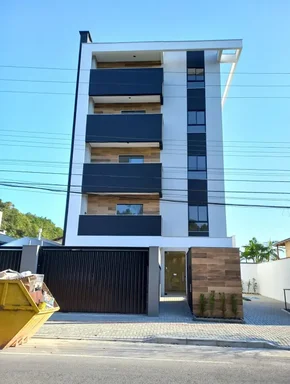
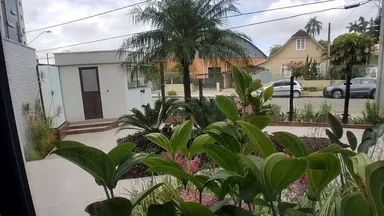
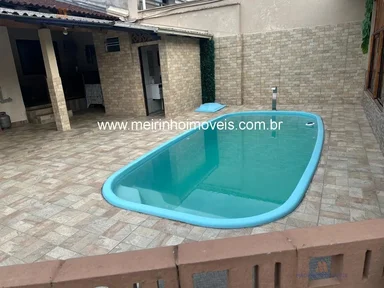
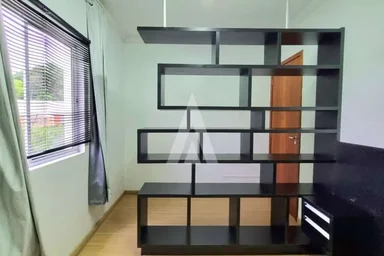

erros adjacentes (maior confianca): 20 fotos



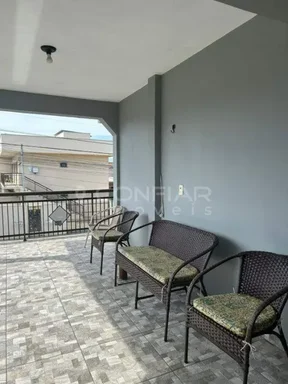
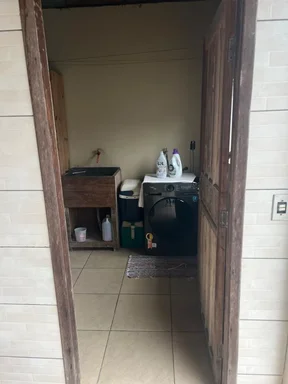
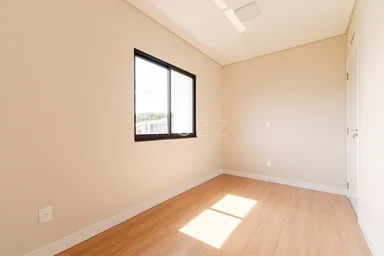
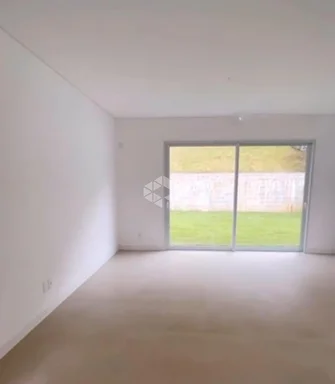
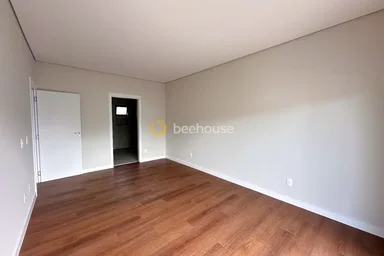
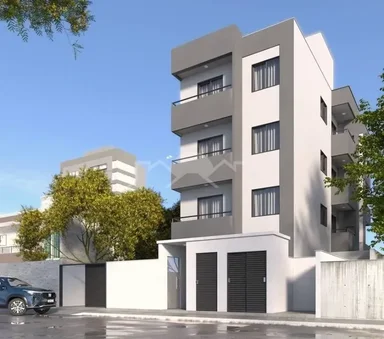
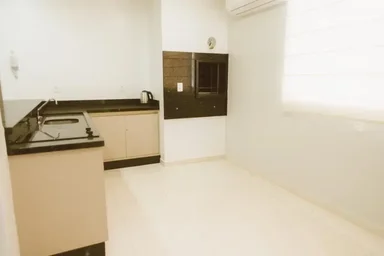
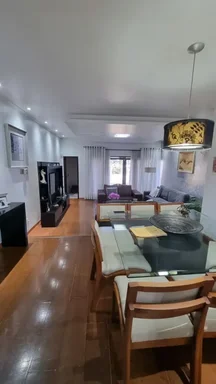
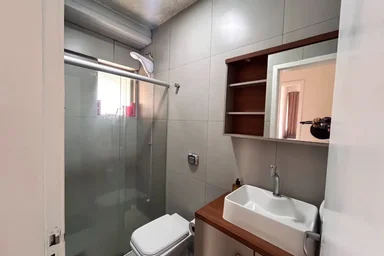
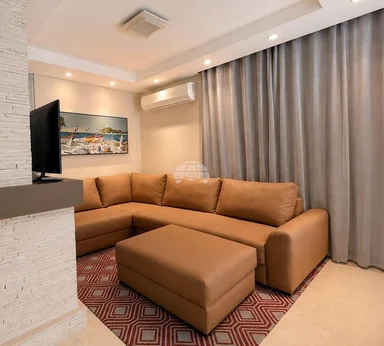
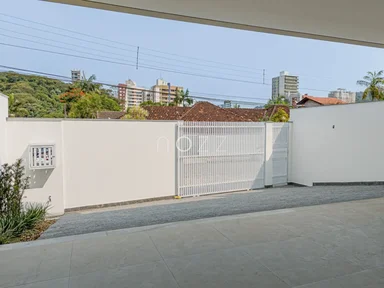
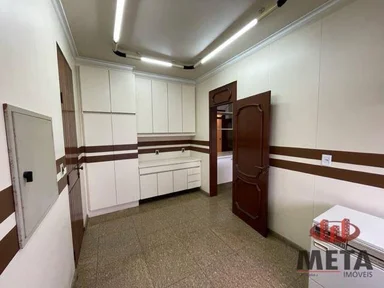
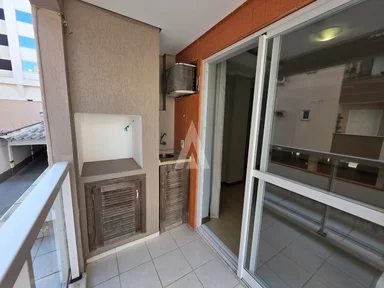
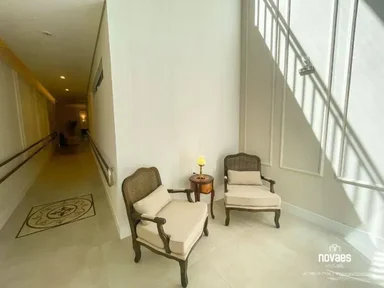
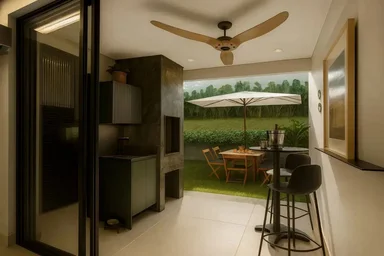
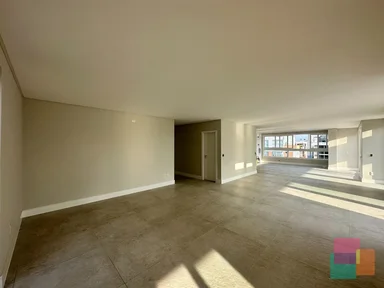
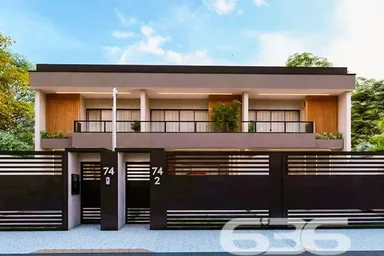
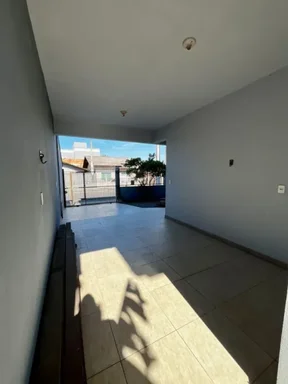
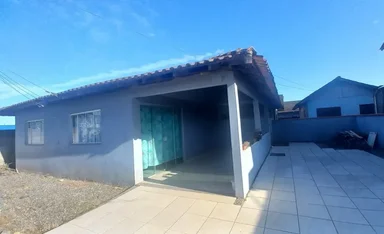
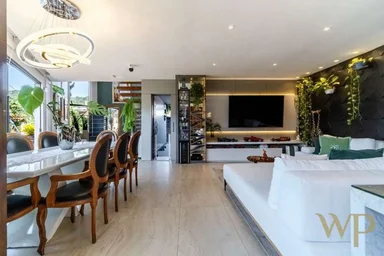

acertos de alta confianca: 12 fotos


humano: desgastadoprevisto: desgastado p=0.96margem 0.94vila nova R$ 330.000,humano: desgastadoprevisto: desgastado p=0.95margem 0.91comasa R$ 309.000,humano: desgastadoprevisto: desgastado p=0.94margem 0.91vila nova R$ 899.997,humano: desgastadoprevisto: desgastado p=0.94margem 0.90iririu R$ 219.000,humano: desgastadoprevisto: desgastado p=0.94margem 0.90espinheiros R$ 359.000,humano: desgaste leveprevisto: desgaste leve p=0.94margem 0.90costa e silva R$ 650.000
humano: desgaste leveprevisto: desgaste leve p=0.93margem 0.90santo antonio R$ 695.000,humano: desgastadoprevisto: desgastado p=0.94margem 0.89costa e silva R$ 835.000,humano: desgastadoprevisto: desgastado p=0.93margem 0.88vila nova R$ 300.000,humano: desgastadoprevisto: desgastado p=0.92margem 0.87iririu R$ 729.900,humano: desgastadoprevisto: desgastado p=0.92margem 0.87gloria R$ 485.000,humano: desgaste leveprevisto: desgaste leve p=0.92margem 0.87vila nova R$ 2.388.000

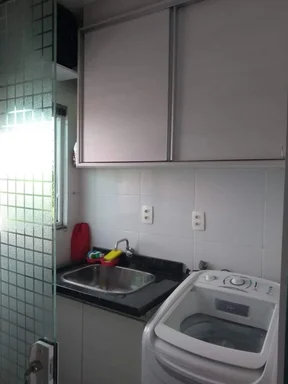
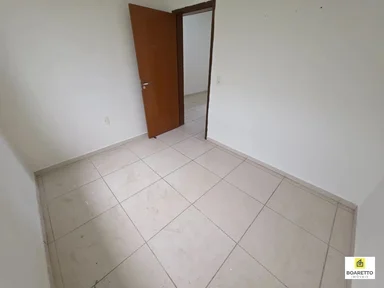
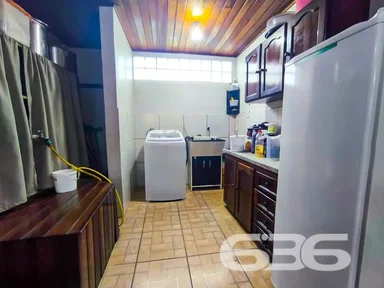
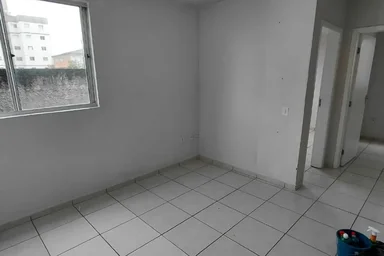
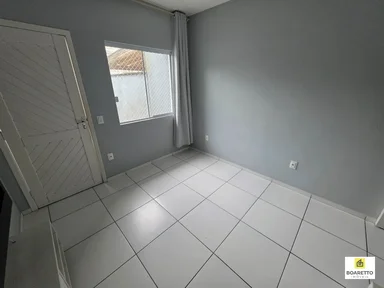
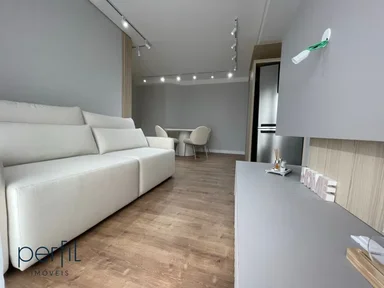
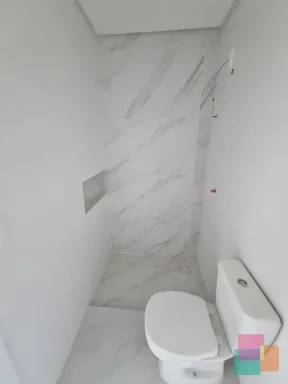
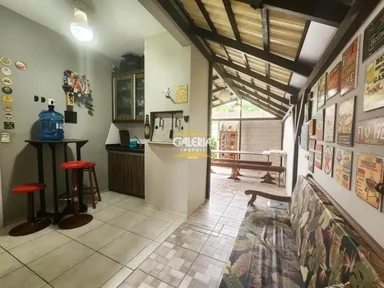
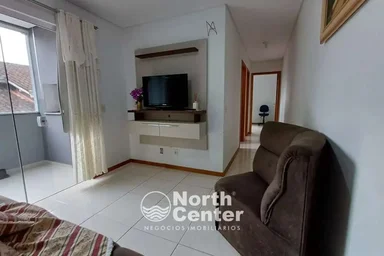
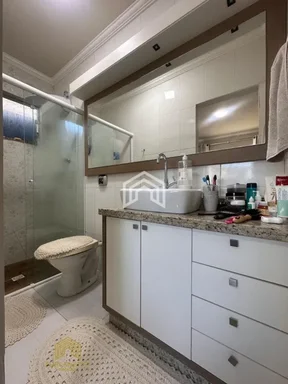
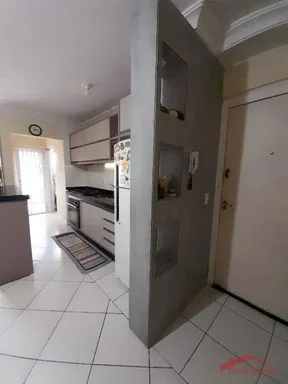
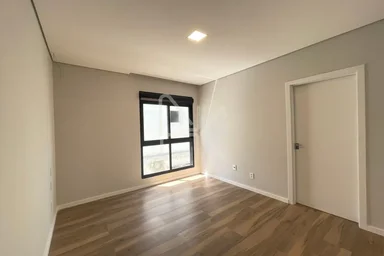

casos de baixa margem: 12 fotos


humano: desgaste leveprevisto: desgastado p=0.41margem 0.00petropolis R$ 480.000,humano: desgaste leveprevisto: desgastado p=0.32margem 0.00costa e silva R$ 550.000,humano: desgaste leveprevisto: bem conservado p=0.30margem 0.00gloria R$ 14.000.000,humano: desgaste leveprevisto: desgaste leve p=0.40margem 0.00guanabara R$ 650.000,humano: precárioprevisto: desgastado p=0.30margem 0.00parque guarani R$ 1.300.000,humano: bem conservadoprevisto: desgaste leve p=0.43margem 0.01america R$ 2.850.000
humano: desgastadoprevisto: bem conservado p=0.43margem 0.01saguacu R$ 315.000,humano: desgastadoprevisto: desgaste leve p=0.35margem 0.01jarivatuba R$ 250.000,humano: desgaste leveprevisto: desgastado p=0.41margem 0.01bom retiro R$ 388.770,humano: desgaste leveprevisto: desgaste leve p=0.44margem 0.01vila nova R$ 2.690.000,humano: desgaste leveprevisto: desgastado p=0.39margem 0.01comasa R$ 620.000,humano: precárioprevisto: precário p=0.36margem 0.01aventureiro R$ 339.000

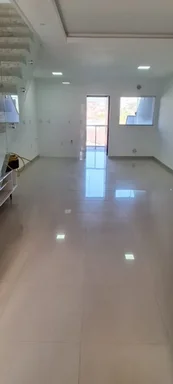
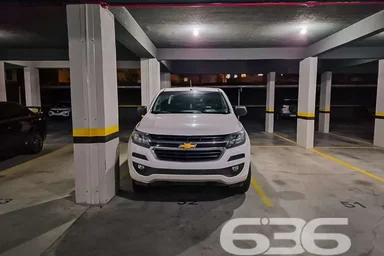
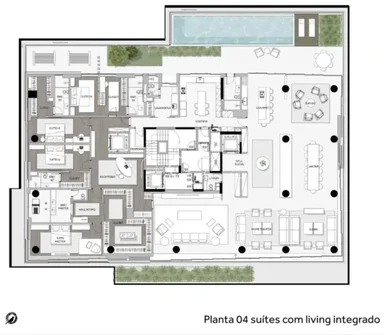
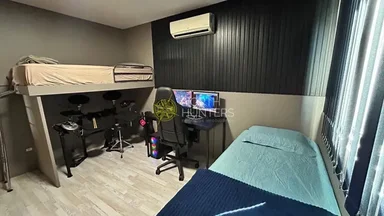
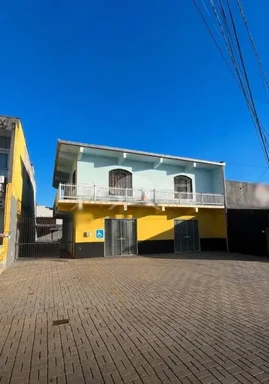
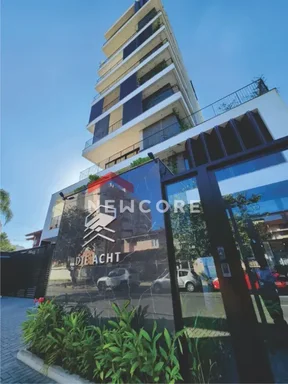
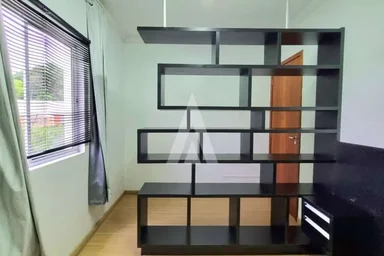
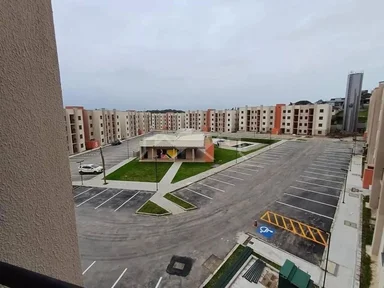
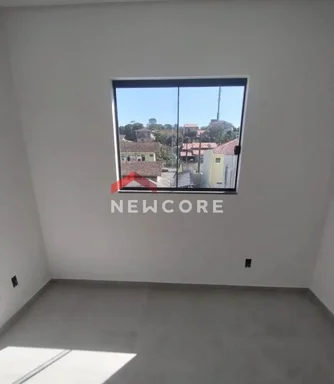
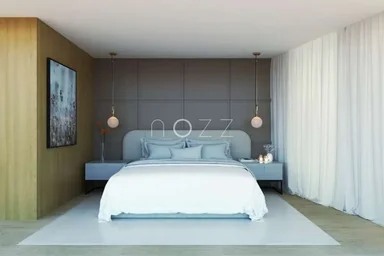
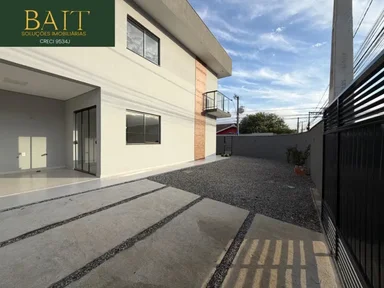
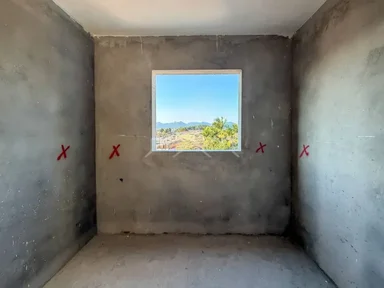

In [11]:
import base64, hashlib
from IPython.display import HTML, display
from classificador_fotos import CACHE

FOTOS_COLUNAS, FOTOS_LARGURA = 6, 190

def _img(url, largura=FOTOS_LARGURA):
    arq = CACHE / (hashlib.sha1(url.encode("utf-8")).hexdigest()[:16] + ".webp")
    if not arq.exists():
        return "<div style='height:120px;color:#888'>sem cache</div>"
    b = base64.b64encode(arq.read_bytes()).decode()
    return (f"<img src='data:image/webp;base64,{b}' width={largura} "
            "style='border-radius:4px;display:block'>")

def _celula(linha, nomes, valor):
    r = linha
    p = r[f"p{r['pred']}"]
    return ("<td style='padding:3px;vertical-align:top;font-size:10px'>"
            + _img(r["url_foto"])
            + f"<br>humano: <b>{nomes[int(r['y'])]}</b>"
            + f"<br>previsto: <b>{nomes[int(r['pred'])]}</b> p={p:.2f}"
            + f"<br>margem {r['margem']:.2f}"
            + f"<br>{r.get('bairro', '')} R$ {valor(r):,.0f}".replace(",", ".") + "</td>")

def galeria(titulo, d, nomes, valor):
    d = d.reset_index(drop=True)
    print(f"{titulo}: {len(d)} fotos")
    partes = ["<table style='border-collapse:collapse'>"]
    for ini in range(0, len(d), FOTOS_COLUNAS):
        partes.append("<tr>" + "".join(
            _celula(d.iloc[i], nomes, valor)
            for i in range(ini, min(ini + FOTOS_COLUNAS, len(d)))) + "</tr>")
    partes.append("</table>")
    display(HTML("".join(partes)))

pr = pd.read_csv(SAIDA / f"probs_oof_conservacao_{IMG}.csv")
hum = pd.read_csv(REPO / "dados" / "rotulos_conservacao.csv",
                  dtype=str, keep_default_na=False)
hum["valor"] = pd.to_numeric(hum["valor_imovel"], errors="coerce").fillna(0)
pr = pr.merge(hum[["url_foto", "bairro", "valor"]], on="url_foto", how="left")
pr["bairro"] = pr["bairro"].fillna("")
pr["valor"] = pr["valor"].fillna(0)
pr["dist"] = (pr["y"] - pr["pred"]).abs()
valor = lambda r: r["valor"]

galeria("erros de 2 niveis", pr[pr.dist == 2].sort_values("margem", ascending=False), LABELS, valor)
galeria("erros adjacentes (maior confianca)", pr[pr.dist == 1].sort_values("margem", ascending=False).head(20), LABELS, valor)
galeria("acertos de alta confianca", pr[pr.dist == 0].sort_values("margem", ascending=False).head(12), LABELS, valor)
galeria("casos de baixa margem", pr.sort_values("margem").head(12), LABELS, valor)

7549 fotos de 775 anuncios | falhas de download: 0
classe modal (modelo) = rotulo humano: 64.1% | fracao modal media: 0.71 | desvio medio intra-anuncio: 0.29
anuncios com |grade - humano| >= 1: 62


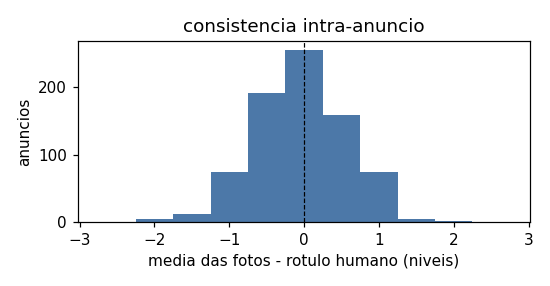

        bairro         humano          modal  frac_modal  grade_medio  grade_desvio  n_fotos
 costa e silva       precário bem conservado        0.50         0.81          0.30       10
       america       precário  desgaste leve        0.70         0.87          0.38       10
      bucarein       precário  desgaste leve        0.90         1.06          0.26       10
  jardim sofia bem conservado     desgastado        0.90         1.82          0.18       10
 jardim iririu       precário  desgaste leve        1.00         1.21          0.13        9
        gloria       precário  desgaste leve        0.40         1.21          0.50       10
       saguacu       precário     desgastado        0.50         1.27          0.61       10
 santo antonio       precário  desgaste leve        0.90         1.28          0.20       10
       saguacu       precário  desgaste leve        0.70         1.34          0.34       10
paranaguamirim       precário     desgastado        0.60         1.44 

In [12]:
import io
from IPython.display import Image, display

def _mostrar_fig(fig, dpi=110):
    buf = io.BytesIO()
    fig.tight_layout()
    fig.savefig(buf, format="png", dpi=dpi)
    plt.close(fig)
    display(Image(buf.getvalue()))


cons = pd.read_csv(SAIDA / "consistencia_anuncios.csv")
i = AVA["irmas"]
print(f"{i['n_fotos']} fotos de {i['n_anuncios']} anuncios | falhas de download: {i['n_falhas']}")
print(f"classe modal (modelo) = rotulo humano: {i['concordancia_modal']:.1%} | "
      f"fracao modal media: {i['frac_modal_medio']:.2f} | "
      f"desvio medio intra-anuncio: {i['grade_desvio_medio']:.2f}")
print("anuncios com |grade - humano| >= 1:", i["discordantes_1nivel"])

fig, ax = plt.subplots(figsize=(5, 2.6))
ax.hist(cons["dif_grade"], bins=np.arange(-2.75, 3.25, 0.5), color="#4c78a8")
ax.axvline(0, color="black", lw=0.8, ls="--")
ax.set_xlabel("media das fotos - rotulo humano (niveis)"); ax.set_ylabel("anuncios")
ax.set_title("consistencia intra-anuncio")
_mostrar_fig(fig); 
top = cons.head(12).copy()
top["humano"] = top["y_humano"].map(dict(enumerate(LABELS)))
top["modal"] = top["pred_modal"].map(dict(enumerate(LABELS)))
print(top[["bairro", "humano", "modal", "frac_modal", "grade_medio",
           "grade_desvio", "n_fotos"]].to_string(index=False,
      float_format=lambda v: f"{v:.2f}"))

**Leitura**: as irmãs não têm rótulo humano — o número compara a **predição do modelo**
nas outras fotos do anúncio com o rótulo humano da foto rotulada. Portanto mistura
erro do modelo com variabilidade real entre cômodos; não é estimativa de ruído de rótulo.

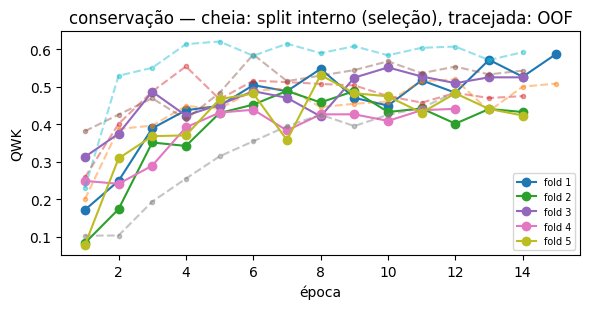

In [13]:
fig, ax = plt.subplots(figsize=(6, 3.2))
for f in MET["conservacao"]["folds"]:
    h = f["historico"]
    ax.plot([e["epoca"] for e in h], [e["val"] for e in h], marker="o",
            label=f"fold {f['fold']}")
    if "val_externa" in h[0]:
        ax.plot([e["epoca"] for e in h], [e["val_externa"] for e in h],
                marker=".", ls="--", alpha=0.45)
ax.set_xlabel("época"); ax.set_ylabel("QWK"); ax.legend(fontsize=7)
ax.set_title("conservação — cheia: split interno (seleção), tracejada: OOF")
plt.tight_layout()

In [ ]:
r = MET["conservacao"]
h = r.get("holdout") or {}
linhas = [(f"CV (n={r['n']})", r["kappa"], f"{r['ic'][0]:.3f}-{r['ic'][1]:.3f}")]
if h:
    linhas.append((f"holdout (n={h['n']})", h["kappa"],
                   f"{h['ic'][0]:.3f}-{h['ic'][1]:.3f}"))
print("ConvNext fine-tune — 775 rotulos humanos:")
print(pd.DataFrame(linhas, columns=["conjunto", "QWK", "IC95"]).to_string(
      index=False, float_format=lambda v: f"{v:.3f}"))
print("referencias de outros conjuntos (nao comparaveis): "
      "LLM v1 QWK 0.041 (400 fotos) | LLM v3 QWK 0.520 (35 fotos)")

lo, hi = r["ic"]
print(f"\nQWK {r['kappa']:.3f} (IC95 {lo:.3f}-{hi:.3f}) | linear "
      f"{r.get('kappa_linear', float('nan')):.3f} | bal_acc {r['balanced_acc']:.3f}"
      f" | macro_f1 {r['macro_f1']:.3f}")
if h:
    print(f"holdout: QWK {h['kappa']:.3f} (IC95 {h['ic'][0]:.3f}-{h['ic'][1]:.3f}) "
          f"| bal_acc {h['balanced_acc']:.3f} | macro_f1 {h['macro_f1']:.3f}")
    lo = min(lo, h["ic"][0])
print("veredito:", "pré-rótulo com revisão" if lo >= 0.55
      else "insuficiente — ampliar rótulos" if hi < 0.40
      else "amostragem para revisão (sem automação)")

ConvNext fine-tune — 775 rotulos humanos:
       conjunto   QWK        IC95
     CV (n=620) 0.514 0.452-0.569
holdout (n=155) 0.443 0.312-0.564
referencias de outros conjuntos (nao comparaveis): LLM v1 QWK 0.041 (400 fotos) | LLM v3 QWK 0.520 (35 fotos)

QWK 0.514 (IC95 0.452-0.569) | linear 0.290 | bal_acc 0.475 | macro_f1 0.492
holdout: QWK 0.443 (IC95 0.312-0.564) | bal_acc 0.436 | macro_f1 0.433
veredito: amostragem para revisão (sem automação)


: 